# SPF EX1 - Alan Jesús Hernández Soto

1.- Se crea un contrato de compra donde se quiere que la acción sea estable. La persona con la que estás haciendo el contrato accede a comprar el 50% de las acciones de tu empresa si la volatilidad móvil con n=20 (anualizada) no excede el 20%. El archivo ex1_01 contiene dos rutas. ¿En cuál de las dos situaciones se activa el contrato?

In [1]:
import pandas as pd
import numpy as np

df = pd.read_excel('ex1_01.xlsx', index_col='Día')
vol_movil_a = []
vol_movil_b = []

df = df.pct_change().dropna()

ruta_a = np.array(df['Ruta A'].values)
ruta_b = np.array(df['Ruta B'].values)


for i in range(len(df)-19):
    vol_movil_a.append(ruta_a[i:20+i].std())
    vol_movil_b.append(ruta_b[i:20+i].std())

vol_movil_a = np.array(vol_movil_a)
vol_movil_b = np.array(vol_movil_b)

print(vol_movil_a.mean()*np.sqrt(252))
print(vol_movil_b.mean()*np.sqrt(252))

0.16583082641129387
0.29623740969128676


**Error 1**
Se concluyo que la volatilidad movil de 16.58% pertenecia a la ruta B mientras pertenecia a la Ruta A, se corrige invirtiendo el nombre de las rutas en la respuesta. Se cometio el error por pasar rapidamente al siguiente ejercicio. Se puede evitar en un futuro el error trabajando de manera mas tranquila y leyendo dos veces.

Se activa en la Ruta A ya que su volatilidad movil es de 16.58% anual mientras que de la ruta B es de 29.62% anual.

2.- Utilizando S0=100, r=0.05, sigma=0.20, T=1, n=252, y un GBM, considera los siguientes supuestos:

A partir del día 30 sabes que el banco central aumentará las tasas de interés al 8%
Sabes que a partir del día 50, después de una junta de accionistas, la volatilidad aumentará a 40% por 20 días; luego de eso, regresará a la normalidad.
Históricamente, las veces que se ha hecho un anuncio importante sobre el portafolio de la empresa para nuevos productos de venta, se producen reacciones fuertemente positivas e inmediatas en el precio de la acción durante 1 semana; se regresa a la normalidad después de esa semana. La presentación está calendarizada para el día 120.

In [2]:
paths = np.zeros((10000, 253))
np.random.seed(123)

paths[:, 0] = 100
# Dia 1-29
for i in range(1, 30):
    paths[:, i] = paths[:, i-1]*np.exp(((0.05-0.5*(0.2**2))*(1/252)) + (0.2*np.sqrt(1/252)*np.random.normal(0,1,10000)))

# Dia 30-49
for i in range(30, 50):
    paths[:, i] = paths[:, i-1]*np.exp(((0.08-0.5*(0.2**2))*(1/252)) + (0.2*np.sqrt(1/252)*np.random.normal(0,1,10000)))

# Dia 50-69
for i in range(50, 70):
    paths[:, i] = paths[:, i-1]*np.exp(((0.08-0.5*(0.4**2))*(1/252)) + (0.4*np.sqrt(1/252)*np.random.normal(0,1,10000)))

# Dia 70-119
for i in range(70, 120):
    paths[:, i] = paths[:, i-1]*np.exp(((0.08-0.5*(0.2**2))*(1/252)) + (0.2*np.sqrt(1/252)*np.random.normal(0,1,10000)))

# Dia 120-126
for i in range(120, 127):
    paths[:, i] = paths[:, i-1]*np.exp(((0.08-0.5*(0.2**2))*(1/252)) + (0.2*np.sqrt(1/252)*np.random.normal(1,1,10000)))

# Dia 127-252
for i in range(127, 253):
    paths[:, i] = paths[:, i-1]*np.exp(((0.08-0.5*(0.2**2))*(1/252)) + (0.2*np.sqrt(1/252)*np.random.normal(0,1,10000)))



**Error 2**
Se interpreto que los cambios solicitados inician hasta al día siguiente del día mencionado mientras que lo mas posible es que los cambios solicitados deberían iniciar en los índices 30, 50 y 120. Se modifican los range para que tenga efecto. Se cometio el error por mala interpretación. Se puede evitar simplemente aclarando la duda.

Se simula dia por dia, dividiendolos manualmente los dias para la simulacion de cada cambio.

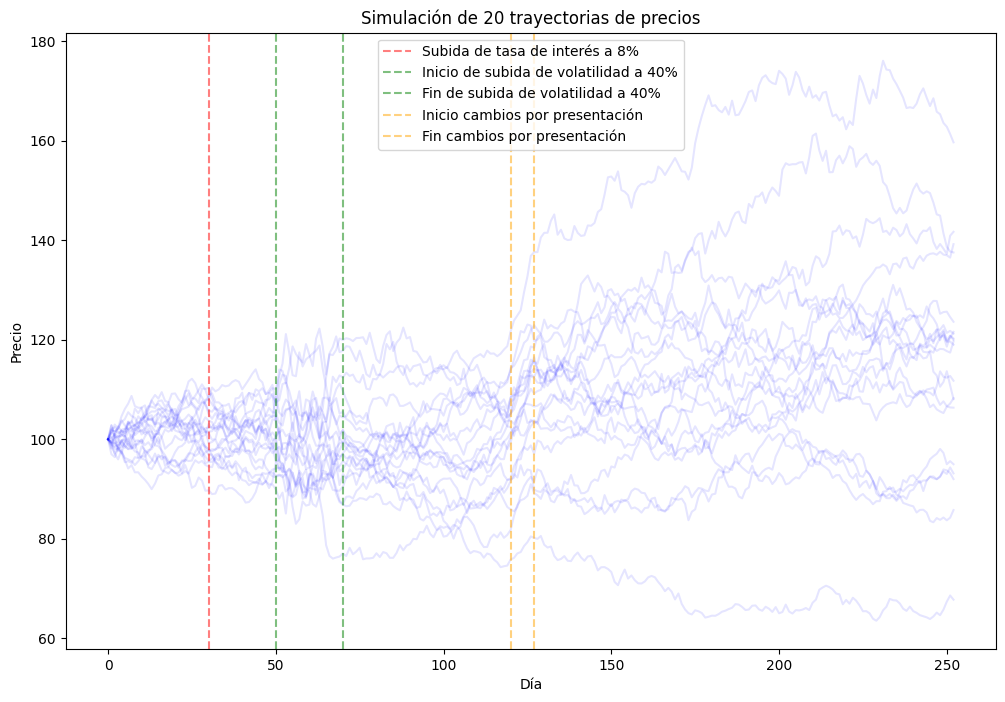

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))
for i in range(20):
    plt.plot(paths[i, :], color='blue', alpha=0.1)
plt.title('Simulación de 20 trayectorias de precios')
plt.xlabel('Día')
plt.ylabel('Precio')
plt.axvline(30, color='red', linestyle='--', label='Subida de tasa de interés a 8%', alpha=0.5)
plt.axvline(50, color='green', linestyle='--', label='Inicio de subida de volatilidad a 40%', alpha=0.5)
plt.axvline(70, color='green', linestyle='--', label='Fin de subida de volatilidad a 40%', alpha=0.5)
plt.axvline(120, color='orange', linestyle='--', label='Inicio cambios por presentación', alpha=0.5)
plt.axvline(127, color='orange', linestyle='--', label='Fin cambios por presentación', alpha=0.5)
plt.legend()
plt.show()

## Examen Escrito

**Error 1**
Se interpreto que la pregunta 'Explica con tus palabras qué significa que las Greeks sean sólo sensibilidades locales.' se referia a que cada opción tiene sus valores propios de Greeks, es decir que cada opcion con una K, tiempo de vencimiento y activo subyacente específicos tenian valores específicos de Greeks. La respuesta correcta es que los Greeks sirven para aproximaciones locales es decir, aproximan el cambio del precio en movimientos pequeños y manteniendo lo demás constante. Se cometío el error ya que no se tenía conocimiento de la respuesta. Se corrige entendiendo de mejor manera la función de los greeks y los supestos en los que se aplica.

**Error 2** Se penso que el 80 era valor atípico y no falta de exactitud.Que el payoff realizado sea 80 y el valor estimado sea 15 no prueba que la simulación esté mal implementada. El valor estimado es una expectativa bajo los supuestos y datos históricos del modelo, esta limitado. Se cometio el error por no pensar en esta posibilidad. Este error se puede evitar aterrizando más a profundidad el tema de Monte Carlo y entendiendo las limitaciones del modelo.

**Error 3** Incrementar el número de simulaciones no se basa en resolver valores atípicos. La respuesta a la pregunta es que incrementar las simulaciones no corrige supuestos erróneos ni la incertidumbre propia del mercado. Puede hacer más precisa una estimación basada en un modelo incorrecto, siendo un modelo inexacto. Se cometío el error por no considerar las diferencias entre precisión y exactitud. Este error de nuevo se puede evitar aterrizando más a profundidad el tema de Monte Carlo y entendiendo las limitaciones del modelo.